# COMPLETION RATE ANALYSIS WITH 5% THRESHOLD

 1. LOAD CLEANED DATASETS

In [1]:
import pandas as pd

df_web = pd.read_csv('02_cleaned_data_files/cleaned_web_events.csv')
df_exp = pd.read_csv('02_cleaned_data_files/cleaned_clients_variation.csv')

# Ensure date_time is in datetime format
df_web['date_time'] = pd.to_datetime(df_web['date_time'])

# Merge web events with experiment client data
df_web_exp = df_web.merge(df_exp, on='client_id', how='inner')

2. COMPLETION RATE ANALYSIS WITH 5% THRESHOLD

In [2]:
# Identify unique clients who reached the 'confirm' step
confirmed_clients = df_web_exp[df_web_exp['process_step'] == 'confirm']['client_id'].unique()

# Calculate total unique clients and completed clients per group
completion_summary = df_web_exp.groupby('Variation')['client_id'].agg(
    total_clients='nunique',
    completed_clients=lambda x: len(set(x).intersection(set(confirmed_clients)))
).reset_index()

# Calculate Completion Rate (%)
completion_summary['completion_rate'] = (
    completion_summary['completed_clients'] / completion_summary['total_clients']
) * 100

print("--- Completion Rate Summary ---")
print(completion_summary)

--- Completion Rate Summary ---
  Variation  total_clients  completed_clients  completion_rate
0   Control          23527              15429        65.579972
1      Test          26961              18682        69.292682


In [3]:
# Extract values for Control and Test
control_cr = completion_summary.loc[completion_summary['Variation'] == 'Control', 'completion_rate'].values[0]
test_cr = completion_summary.loc[completion_summary['Variation'] == 'Test', 'completion_rate'].values[0]

In [4]:
# Calculate absolute increase (percentage points difference)
observed_increase = test_cr - control_cr
threshold = 5.0  # 5% threshold required by Vanguard

print(f"\nControl Completion Rate: {control_cr:.2f}%")
print(f"Test Completion Rate: {test_cr:.2f}%")
print(f"Observed Difference (Test - Control): {observed_increase:+.2f}%")

if observed_increase >= threshold:
    print(f"\nResult: The observed increase ({observed_increase:.2f}%) exceeds the threshold ({threshold}%).")
else:
    print(f"\nResult: The observed increase ({observed_increase:.2f}%) does not exceed the threshold ({threshold}%).")


Control Completion Rate: 65.58%
Test Completion Rate: 69.29%
Observed Difference (Test - Control): +3.71%

Result: The observed increase (3.71%) does not exceed the threshold (5.0%).


3. COST-EFFECTIVENESS EVALUATION

In [5]:
print("\n--- Cost-Effectiveness Evaluation ---")
if observed_increase >= threshold:
    print(f"SUCCESS: The observed increase ({observed_increase:.2f}%) meets or exceeds the {threshold:.1f}% threshold.")
else:
    print(f"FAIL: The observed increase ({observed_increase:.2f}%) is BELOW the required {threshold:.1f}% threshold.")


--- Cost-Effectiveness Evaluation ---
FAIL: The observed increase (3.71%) is BELOW the required 5.0% threshold.


# INSIGHT & BUSINESS RECOMMENDATION

1. Completion Rate Improvement:The new UI design increased the completion rate from 65.58% to 69.29% (+3.71%).
2. Threshold Assessment:
The minimum required threshold for cost-effectiveness was set at 5.0%. Since the observed uplift (+3.71%) falls short of this threshold by 1.29 percentage points, the new design is not financially justifiable.   
3. Final Recommendation:
REJECT or REVISE the new UI design before full deployment.   

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
custom_palette = {"Control": "#4C72B0", "Test": "#DD8452"}

# =========================================================
# 1. LOAD CLEANED DATASETS & PREPARE DATA
# =========================================================
df_web = pd.read_csv('02_cleaned_data_files/cleaned_web_events.csv')
df_exp = pd.read_csv('02_cleaned_data_files/cleaned_clients_variation.csv')
df_web_exp = df_web.merge(df_exp, on='client_id', how='inner')

# Identify confirmed clients
confirmed_clients = set(df_web_exp[df_web_exp['process_step'] == 'confirm']['client_id'])

# Completion rate aggregation
completion_df = df_web_exp.groupby('Variation')['client_id'].agg(
    total_clients='nunique',
    completed_clients=lambda x: len(set(x).intersection(confirmed_clients))
).reset_index()

completion_df['completion_rate'] = (completion_df['completed_clients'] / completion_df['total_clients']) * 100

# =========================================================

# =========================================================





































# =========================================================
# 
# =========================================================

CHART 1: COMPLETION RATE VS 5% THRESHOLD

C:\Users\yurii\AppData\Local\Temp\ipykernel_35560\3809655248.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(


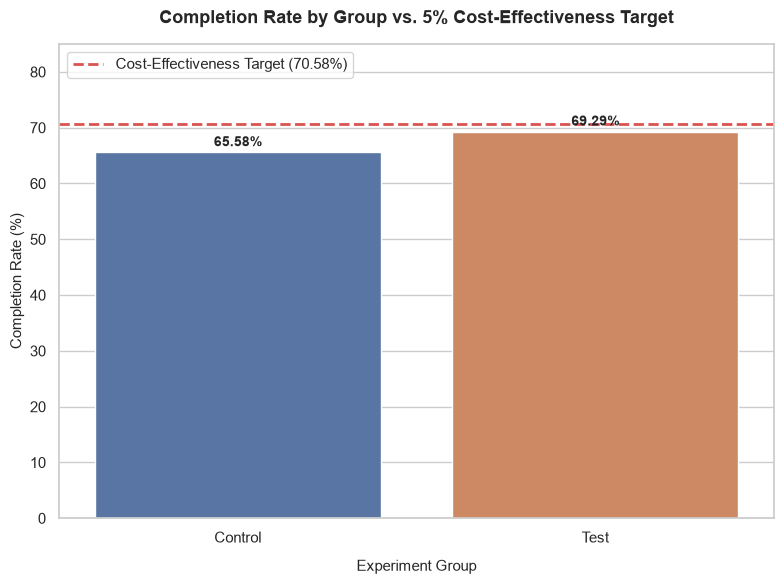

In [8]:
plt.figure(figsize=(8, 6))                                                                                    
ax1 = sns.barplot(                                                                                            
    data=completion_df,                                                                                       
    x='Variation',                                                                                            
    y='completion_rate',                                                                                      
    palette=custom_palette                                                                                    
)                                                                                                             
                                                                                                              
                                                                                                              
# Extract Control rate and calculate 5% target threshold                                                      
control_cr = completion_df.loc[completion_df['Variation'] == 'Control', 'completion_rate'].values[0]          
target_threshold = control_cr + 5.0                                                                           
                                                                                                              
                                                                                                              
# Add target threshold line                                                                                   
plt.axhline(                                                                                                  
    y=target_threshold,                                                                                       
    color='#D9534F',                                                                                          
    linestyle='--',                                                                                           
    linewidth=2,                                                                                              
    label=f'Cost-Effectiveness Target ({target_threshold:.2f}%)'                                              
)                                                                                                             
                                                                                                              
                                                                                                              
plt.title('Completion Rate by Group vs. 5% Cost-Effectiveness Target', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Experiment Group', fontsize=11, labelpad=10)                                                      
plt.ylabel('Completion Rate (%)', fontsize=11)                                                                
plt.ylim(0, 85)                                                                                               
plt.legend(loc='upper left', frameon=True)                                                                    
                                                                                                              
                                                                                                              
# Add data values on top of bars                                                                              
for p in ax1.patches:                                                                                         
    height = p.get_height()                                                                                   
    ax1.annotate(                                                                                             
        f'{height:.2f}%',                                                                                     
        (p.get_x() + p.get_width() / 2., height),                                                             
        ha='center', va='center',                                                                             
        xytext=(0, 7),                                                                                        
        textcoords='offset points',                                                                           
        fontsize=10, fontweight='bold'                                                                        
    )                                                                                                         
                                                                                                              
                                                                                                              
plt.tight_layout()                                                                                            
plt.show()                                                                                                    

Chart 1 (Completion Rate vs. Target):
Clearly highlights how the Test group bar (69.29%) remains below the red dashed line of the business target (70.58%), visually explaining why the project fails to meet the cost-effectiveness threshold.

CHART 2: PROCESS FUNNEL (USER RETENTION PER STEP)

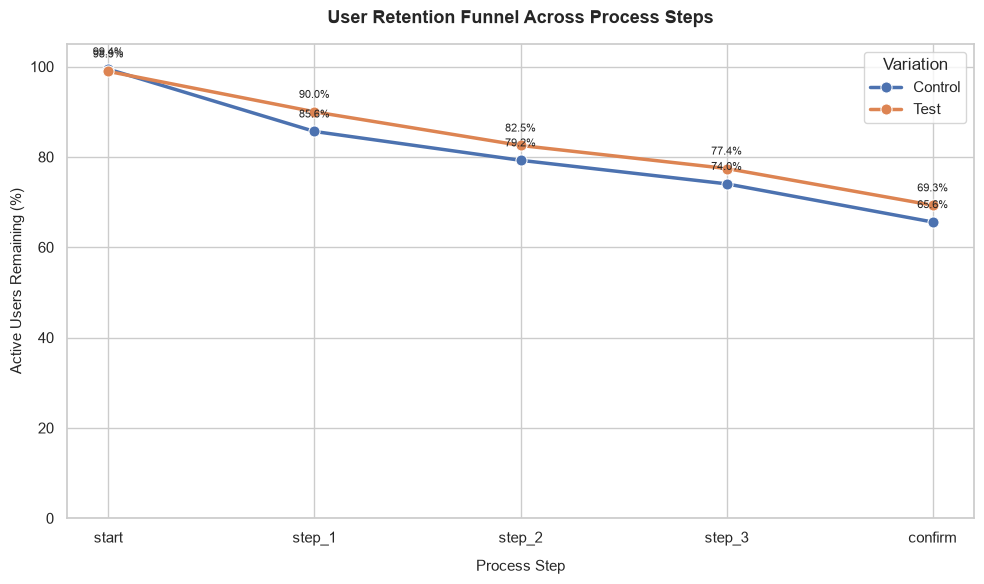

In [9]:
step_order = ['start', 'step_1', 'step_2', 'step_3', 'confirm']                                               
                                                                                                              
                                                                                                              
# Count unique clients per step and variation                                                                 
funnel_data = df_web_exp.groupby(['Variation', 'process_step'])['client_id'].nunique().reset_index()          
                                                                                                              
                                                                                                              
# Get total starting clients per group for percentage calculation                                             
total_per_group = df_web_exp.groupby('Variation')['client_id'].nunique().to_dict()                            
funnel_data['retention_rate'] = funnel_data.apply(                                                            
    lambda row: (row['client_id'] / total_per_group[row['Variation']]) * 100, axis=1                          
)                                                                                                             
                                                                                                              
                                                                                                              
# Sort steps logically                                                                                        
funnel_data['process_step'] = pd.Categorical(funnel_data['process_step'], categories=step_order, ordered=True)
funnel_data = funnel_data.sort_values(['Variation', 'process_step'])                                          
                                                                                                              
                                                                                                              
plt.figure(figsize=(10, 6))                                                                                   
ax2 = sns.lineplot(                                                                                           
    data=funnel_data,                                                                                         
    x='process_step',                                                                                         
    y='retention_rate',                                                                                       
    hue='Variation',                                                                                          
    marker='o',                                                                                               
    linewidth=2.5,                                                                                            
    markersize=8,                                                                                             
    palette=custom_palette                                                                                    
)                                                                                                             
                                                                                                              
                                                                                                              
plt.title('User Retention Funnel Across Process Steps', fontsize=13, fontweight='bold', pad=15)               
plt.xlabel('Process Step', fontsize=11, labelpad=10)                                                          
plt.ylabel('Active Users Remaining (%)', fontsize=11)                                                         
plt.ylim(0, 105)                                                                                              
plt.legend(title='Variation', frameon=True)                                                                   
                                                                                                              
                                                                                                              
# Annotate points with percentages                                                                            
for _, row in funnel_data.iterrows():                                                                         
    ax2.annotate(                                                                                             
        f"{row['retention_rate']:.1f}%",                                                                      
        (row['process_step'], row['retention_rate']),                                                         
        textcoords="offset points",                                                                           
        xytext=(0, 10),                                                                                       
        ha='center',                                                                                          
        fontsize=8                                                                                            
    )                                                                                                         
                                                                                                              
                                                                                                              
plt.tight_layout()                                                                                            
plt.show()                                                                                                    

Chart 2 (Navigation Funnel):
Displays the user drop-off curve from the initial 'start' step to the final 
confirm' step, comparing the efficiency of both designs at each stage of the process.